In [1]:
import pandas as pd
import numpy as np

# Random seed for reproducibility
np.random.seed(42)

# Create base dataset
routes = ["DXB-COK","DXB-DEL","DXB-MAA","DXB-BLR","DXB-TRV","DXB-HYD"]
flights = [f"G9 {100+i}" for i in range(50)]

data = {
    "No": range(1,51),
    "Flight": flights,
    "Passengers": np.random.randint(120,250,50),
    "Revenue": np.random.randint(60000,120000,50),
    "Route": np.random.choice(routes,50),
    "YearMonth": pd.date_range("2025-01-01", periods=50, freq="ME"),
    "Capacity": np.random.randint(180,260,50)
}

df = pd.DataFrame(data)

In [2]:
# -----------------------------
# Step 2 – Inject Messy Scenarios
# -----------------------------

# 1. NaN values
df.loc[5,"Revenue"] = np.nan
df.loc[10,"Passengers"] = np.nan
df.loc[15,"Capacity"] = np.nan

# 2. Spelling mistakes
df.loc[20,"Route"] = "Delhii"
df.loc[25,"Route"] = "DXB-COC"

# 3. Irregular cases
df.loc[30,"Route"] = "dxb-cok"
df.loc[35,"Route"] = "Dxb-Del"

# 4. Duplicates
df = pd.concat([df, df.iloc[[2,8]]], ignore_index=True)

# 5. Outliers
df.loc[40,"Revenue"] = 999999   # unusually high
df.loc[45,"Revenue"] = 1000     # unusually low

# 6. Add Revenue per Passenger (with NaN handling)
df["Revenue_per_Passenger"] = df["Revenue"] / df["Passengers"]



In [3]:
# Preview messy dataset
print(df.head(15))

    No  Flight  Passengers   Revenue    Route  YearMonth  Capacity  \
0    1  G9 100       222.0   73417.0  DXB-DEL 2025-01-31     236.0   
1    2  G9 101       212.0  112995.0  DXB-DEL 2025-02-28     185.0   
2    3  G9 102       134.0  100757.0  DXB-COK 2025-03-31     207.0   
3    4  G9 103       226.0   69692.0  DXB-BLR 2025-04-30     207.0   
4    5  G9 104       191.0  105758.0  DXB-COK 2025-05-31     223.0   
5    6  G9 105       140.0       NaN  DXB-BLR 2025-06-30     209.0   
6    7  G9 106       222.0   65675.0  DXB-DEL 2025-07-31     241.0   
7    8  G9 107       241.0   60161.0  DXB-COK 2025-08-31     254.0   
8    9  G9 108       194.0   97065.0  DXB-HYD 2025-09-30     241.0   
9   10  G9 109       207.0   86557.0  DXB-TRV 2025-10-31     180.0   
10  11  G9 110         NaN   93763.0  DXB-MAA 2025-11-30     206.0   
11  12  G9 111       219.0   92606.0  DXB-BLR 2025-12-31     241.0   
12  13  G9 112       223.0   71534.0  DXB-HYD 2026-01-31     256.0   
13  14  G9 113      

In [4]:
print(df.tail(15))

    No  Flight  Passengers   Revenue    Route  YearMonth  Capacity  \
37  38  G9 137       209.0   62568.0  DXB-TRV 2028-02-29     181.0   
38  39  G9 138       172.0  114615.0  DXB-MAA 2028-03-31     233.0   
39  40  G9 139       249.0   62027.0  DXB-TRV 2028-04-30     180.0   
40  41  G9 140       203.0  999999.0  DXB-BLR 2028-05-31     198.0   
41  42  G9 141       211.0  118839.0  DXB-TRV 2028-06-30     181.0   
42  43  G9 142       230.0  108190.0  DXB-MAA 2028-07-31     232.0   
43  44  G9 143       127.0   65258.0  DXB-MAA 2028-08-31     223.0   
44  45  G9 144       154.0   82002.0  DXB-HYD 2028-09-30     211.0   
45  46  G9 145       200.0    1000.0  DXB-BLR 2028-10-31     249.0   
46  47  G9 146       169.0   93159.0  DXB-DEL 2028-11-30     211.0   
47  48  G9 147       223.0   73986.0  DXB-DEL 2028-12-31     247.0   
48  49  G9 148       121.0   72666.0  DXB-TRV 2029-01-31     234.0   
49  50  G9 149       173.0   98660.0  DXB-HYD 2029-02-28     254.0   
50   3  G9 102      

In [5]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 52 entries, 0 to 51
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   No                     52 non-null     int64         
 1   Flight                 52 non-null     str           
 2   Passengers             51 non-null     float64       
 3   Revenue                51 non-null     float64       
 4   Route                  52 non-null     str           
 5   YearMonth              52 non-null     datetime64[us]
 6   Capacity               51 non-null     float64       
 7   Revenue_per_Passenger  50 non-null     float64       
dtypes: datetime64[us](1), float64(4), int64(1), str(2)
memory usage: 3.4 KB
None


In [6]:
print(df.describe(include='all'))


               No  Flight  Passengers        Revenue    Route  \
count   52.000000      52   51.000000      51.000000       52   
unique        NaN      50         NaN            NaN       10   
top           NaN  G9 102         NaN            NaN  DXB-TRV   
freq          NaN       2         NaN            NaN       10   
mean    24.750000     NaN  182.215686  104554.921569      NaN   
min      1.000000     NaN  121.000000    1000.000000      NaN   
25%     11.750000     NaN  147.500000   72425.500000      NaN   
50%     24.500000     NaN  179.000000   86557.000000      NaN   
75%     37.250000     NaN  210.000000  100757.000000      NaN   
max     50.000000     NaN  249.000000  999999.000000      NaN   
std     14.793845     NaN   36.636219  129580.341328      NaN   

                         YearMonth    Capacity  Revenue_per_Passenger  
count                           52   51.000000              50.000000  
unique                         NaN         NaN                    NaN  
top

In [7]:
df.isnull().sum()

No                       0
Flight                   0
Passengers               1
Revenue                  1
Route                    0
YearMonth                0
Capacity                 1
Revenue_per_Passenger    2
dtype: int64

In [8]:
df.fillna(0, inplace=True)


,No,Flight,Passengers,Revenue,Route,YearMonth,Capacity,Revenue_per_Passenger
0,1,G9 100,222.0,73417.0,DXB-DEL,2025-01-31,236.0,330.707207
1,2,G9 101,212.0,112995.0,DXB-DEL,2025-02-28,185.0,532.995283
2,3,G9 102,134.0,100757.0,DXB-COK,2025-03-31,207.0,751.917910
3,4,G9 103,226.0,69692.0,DXB-BLR,2025-04-30,207.0,308.371681
4,5,G9 104,191.0,105758.0,DXB-COK,2025-05-31,223.0,553.706806
5,6,G9 105,140.0,0.0,DXB-BLR,2025-06-30,209.0,0.000000
6,7,G9 106,222.0,65675.0,DXB-DEL,2025-07-31,241.0,295.833333
7,8,G9 107,241.0,60161.0,DXB-COK,2025-08-31,254.0,249.630705
8,9,G9 108,194.0,97065.0,DXB-HYD,2025-09-30,241.0,500.335052
9,10,G9 109,207.0,86557.0,DXB-TRV,2025-10-31,180.0,418.149758


In [9]:
df.isnull().sum()

No                       0
Flight                   0
Passengers               0
Revenue                  0
Route                    0
YearMonth                0
Capacity                 0
Revenue_per_Passenger    0
dtype: int64

In [10]:
df.Route.str.upper().str.strip()  # Convert to uppercase and remove leading/trailing whitespace
df.replace({"Route": {"Delhii": "DXB-DEL", "DXB-COC": "DXB-COK", "dxb-cok": "DXB-COK", "Dxb-Del": "DXB-DEL"}}, inplace=True)

# Replace the Route column with cleaned values

,No,Flight,Passengers,Revenue,Route,YearMonth,Capacity,Revenue_per_Passenger
0,1,G9 100,222.0,73417.0,DXB-DEL,2025-01-31,236.0,330.707207
1,2,G9 101,212.0,112995.0,DXB-DEL,2025-02-28,185.0,532.995283
2,3,G9 102,134.0,100757.0,DXB-COK,2025-03-31,207.0,751.917910
3,4,G9 103,226.0,69692.0,DXB-BLR,2025-04-30,207.0,308.371681
4,5,G9 104,191.0,105758.0,DXB-COK,2025-05-31,223.0,553.706806
5,6,G9 105,140.0,0.0,DXB-BLR,2025-06-30,209.0,0.000000
6,7,G9 106,222.0,65675.0,DXB-DEL,2025-07-31,241.0,295.833333
7,8,G9 107,241.0,60161.0,DXB-COK,2025-08-31,254.0,249.630705
8,9,G9 108,194.0,97065.0,DXB-HYD,2025-09-30,241.0,500.335052
9,10,G9 109,207.0,86557.0,DXB-TRV,2025-10-31,180.0,418.149758


In [11]:
df.Route.unique()

# To find unique routes and their counts


<StringArray>
['DXB-DEL', 'DXB-COK', 'DXB-BLR', 'DXB-HYD', 'DXB-TRV', 'DXB-MAA']
Length: 6, dtype: str

In [12]:
df.duplicated().any() # if any duplicated is there ?



np.True_

In [13]:
df.duplicated().sum() # Count of duplicated rows

np.int64(2)

In [14]:
df[df.duplicated(keep=False)]  # Display all duplicated rows if any

,No,Flight,Passengers,Revenue,Route,YearMonth,Capacity,Revenue_per_Passenger
2,3,G9 102,134.0,100757.0,DXB-COK,2025-03-31,207.0,751.917910
8,9,G9 108,194.0,97065.0,DXB-HYD,2025-09-30,241.0,500.335052
50,3,G9 102,134.0,100757.0,DXB-COK,2025-03-31,207.0,751.917910
51,9,G9 108,194.0,97065.0,DXB-HYD,2025-09-30,241.0,500.335052


In [15]:
df.drop_duplicates(inplace = True)

In [16]:
df.duplicated().sum() 

# Think of it like this:

# duplicated() = flags duplicates.

# duplicated(keep=False) = shows the full duplicate groups.

# drop_duplicates() = removes them.

np.int64(0)

In [17]:
route_perf = df.groupby("Route")["Revenue"].sum()
route_contribution = (route_perf / route_perf.sum()) * 100
print(route_contribution.sort_values(ascending=False))


# Formula:
# Route Contribution % = Revenue of a Route 
#                              Divide             X 100
#                          Total Revenue         


Route
DXB-BLR    28.623274
DXB-TRV    16.589200
DXB-DEL    16.231832
DXB-MAA    15.306519
DXB-COK    12.690869
DXB-HYD    10.558306
Name: Revenue, dtype: float64


In [18]:
df["YearQuater"] = df["YearMonth"].dt.to_period("Q")
quarterly_revenue = df.groupby("YearQuater")["Revenue"].sum()
print(quarterly_revenue)

# Foundation for Growth Metrics → You need quarters to calculate QoQ growth and YOY growth.


YearQuater
2025Q1     287169.0
2025Q2     175450.0
2025Q3     222901.0
2025Q4     272926.0
2026Q1     261058.0
2026Q2     231120.0
2026Q3     283114.0
2026Q4     230091.0
2027Q1     222724.0
2027Q2     248913.0
2027Q3     315856.0
2027Q4     329414.0
2028Q1     277957.0
2028Q2    1180865.0
2028Q3     255450.0
2028Q4     168145.0
2029Q1     171326.0
Freq: Q-DEC, Name: Revenue, dtype: float64


In [19]:
qoq_growth = quarterly_revenue.pct_change() * 100
print(qoq_growth)


# QoQ Growth = Current Quarter Revenue - Previous Quarter Revenue 
#              --------------------divide------------------------    X 100
#                          Previous Quarter Revenue

YearQuater
2025Q1           NaN
2025Q2    -38.903572
2025Q3     27.045312
2025Q4     22.442699
2026Q1     -4.348431
2026Q2    -11.467950
2026Q3     22.496539
2026Q4    -18.728498
2027Q1     -3.201777
2027Q2     11.758499
2027Q3     26.894136
2027Q4      4.292462
2028Q1    -15.620769
2028Q2    324.837295
2028Q3    -78.367553
2028Q4    -34.176943
2029Q1      1.891820
Freq: Q-DEC, Name: Revenue, dtype: float64


In [20]:
yearly_revenue = df.groupby(df["YearMonth"].dt.year)["Revenue"].sum()


In [21]:
yoy_growth = quarterly_revenue.groupby(quarterly_revenue.index.quarter).pct_change() * 100
print(yoy_growth)


YearQuater
2025Q1           NaN
2025Q2           NaN
2025Q3           NaN
2025Q4           NaN
2026Q1     -9.092555
2026Q2     31.729838
2026Q3     27.013338
2026Q4    -15.694730
2027Q1    -14.684093
2027Q2      7.698598
2027Q3     11.564953
2027Q4     43.166834
2028Q1     24.798854
2028Q2    374.408729
2028Q3    -19.124538
2028Q4    -48.956329
2029Q1    -38.362409
Freq: Q-DEC, Name: Revenue, dtype: float64


In [22]:
yearly_revenue = df.groupby(df["YearMonth"].dt.year)["Revenue"].sum()
yearly_growth = yearly_revenue.pct_change() * 100


In [23]:
summary = pd.DataFrame({
    "Quarterly_Revenue": quarterly_revenue,
    "QoQ_Growth_%": qoq_growth,
    "YOY_Growth_%": yoy_growth
})

print(summary)
print("\nYearly Revenue & Growth:")
print(pd.DataFrame({"Yearly_Revenue": yearly_revenue, "Yearly_Growth_%": yearly_growth}))


            Quarterly_Revenue  QoQ_Growth_%  YOY_Growth_%
YearQuater                                               
2025Q1               287169.0           NaN           NaN
2025Q2               175450.0    -38.903572           NaN
2025Q3               222901.0     27.045312           NaN
2025Q4               272926.0     22.442699           NaN
2026Q1               261058.0     -4.348431     -9.092555
2026Q2               231120.0    -11.467950     31.729838
2026Q3               283114.0     22.496539     27.013338
2026Q4               230091.0    -18.728498    -15.694730
2027Q1               222724.0     -3.201777    -14.684093
2027Q2               248913.0     11.758499      7.698598
2027Q3               315856.0     26.894136     11.564953
2027Q4               329414.0      4.292462     43.166834
2028Q1               277957.0    -15.620769     24.798854
2028Q2              1180865.0    324.837295    374.408729
2028Q3               255450.0    -78.367553    -19.124538
2028Q4        

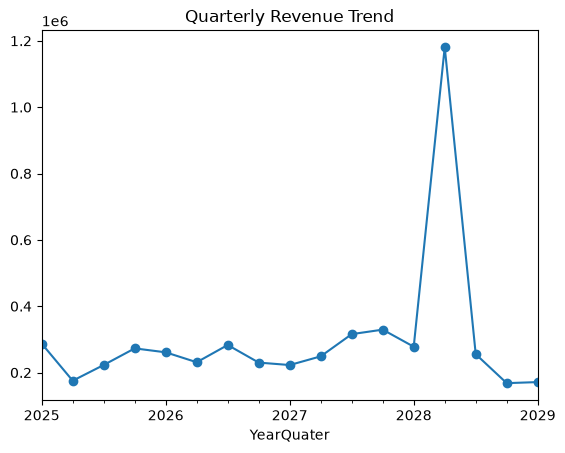

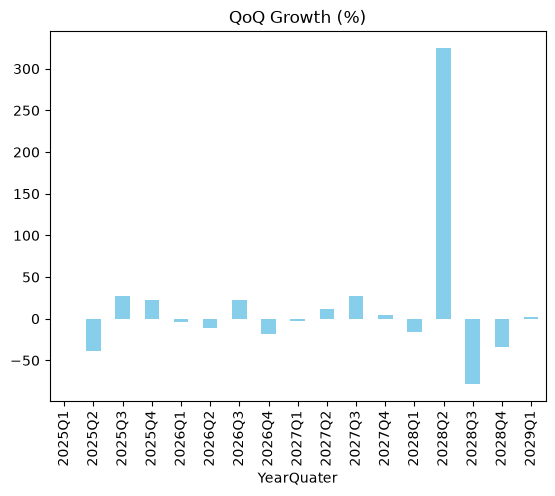

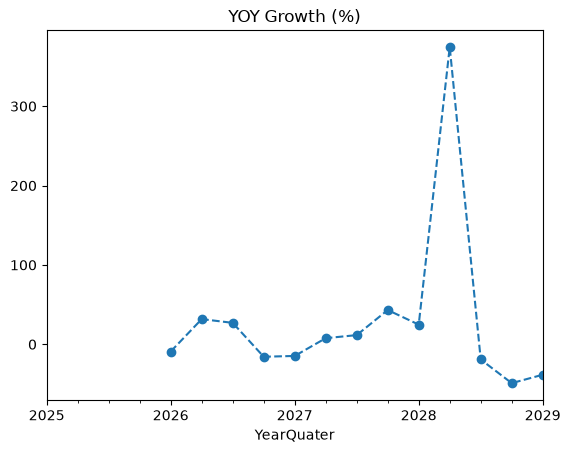

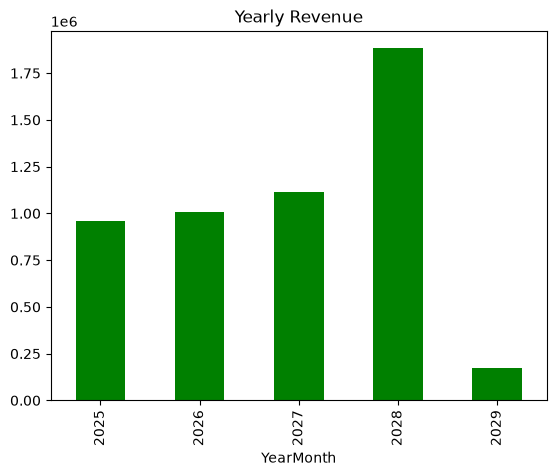

In [24]:
import matplotlib.pyplot as plt

# Quarterly Revenue Trend
quarterly_revenue.plot(kind="line", marker="o", title="Quarterly Revenue Trend")
plt.show()

# QoQ Growth Bar Chart
qoq_growth.plot(kind="bar", color="skyblue", title="QoQ Growth (%)")
plt.show()

# YOY Growth Line Chart
yoy_growth.plot(kind="line", marker="o", linestyle="--", title="YOY Growth (%)")
plt.show()

# Yearly Revenue Trend
yearly_revenue.plot(kind="bar", color="green", title="Yearly Revenue")
plt.show()


In [27]:

route_perf = df.groupby("Route")["Revenue"].sum()
route_contribution = (route_perf / route_perf.sum()) * 100
top_routes = route_contribution.sort_values(ascending=False).head(5)



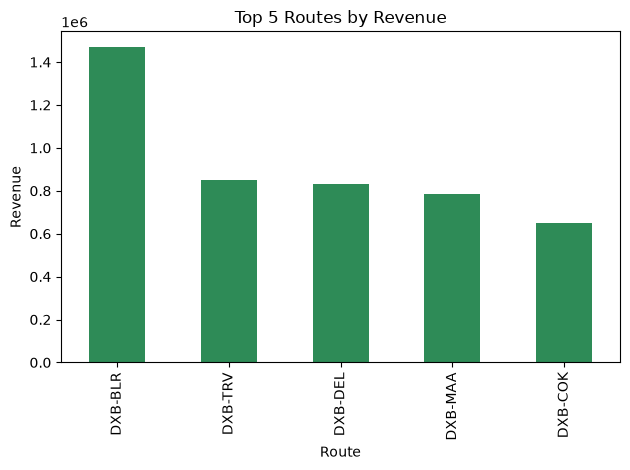

In [33]:
top_profitable_routes = route_perf.nlargest(5)

top_profitable_routes.plot(
    kind="bar",
    color="seagreen",
    title="Top 5 Routes by Revenue",
    ylabel="Revenue",
    xlabel="Route"
)

plt.tight_layout()
plt.show()
